# Digital Audio Synthesizer and Effects Rack
**Signals and Systems | Sharif University of Technology**  
**Farzan Aghaei · Sanaz Mazrae**

An end-to-end implementation of waveform oscillators, detuned voices, an AHDSR envelope, MIDI-to-audio rendering, voltage-controlled filtering, and a configurable series effects rack. The demonstrations include all effect families implemented in the project: hard/soft/variable saturation, compression, fixed and modulated delay, fixed and modulated phasing/flanging/chorus, algorithmic and convolution reverberation, VCF, vocoder, and pitch shifting.

All demonstrations use audio or MIDI files supplied with the original project. Generated audio is saved as WAV files to `outputs/`. The notebook executes in order without interactive input or audio-hardware dependencies.

## 1. Environment, sample assets and signal conventions
Audio is processed internally as floating-point samples. Output WAV files are saved at the specified sample rate as PCM-16 after a final peak-limit when needed. Time-domain illustrations use a fixed analysis window; quantitative plots operate on saved signals. Source material is mono for the standard effects; the original stereo room impulse responses are downmixed consistently for convolution.

In [1]:
from pathlib import Path
from dataclasses import dataclass
from collections import defaultdict, deque
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import soundfile as sf
import mido
from IPython.display import display, Audio

FS = 44100
BASE = Path.cwd()
ASSETS = BASE / 'assets'
OUT = BASE / 'outputs'
FIG = BASE / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
assert (ASSETS / 'newSong.mid').exists(), 'Run from the repository root.'
np.set_printoptions(precision=4, suppress=True)

def mono(data):
    arr=np.asarray(data, dtype=np.float64)
    return arr.mean(axis=1) if arr.ndim == 2 else arr

def read_audio(name, rate=FS, limit_seconds=None):
    data, sr = sf.read(ASSETS/name, always_2d=False)
    data=mono(data)
    if sr != rate:
        data=signal.resample_poly(data, rate//math.gcd(sr,rate), sr//math.gcd(sr,rate))
    if limit_seconds is not None:
        data=data[:int(limit_seconds*rate)]
    return data

def save_audio(name, data, rate=FS):
    x=np.asarray(data, dtype=np.float64)
    if not np.all(np.isfinite(x)):
        raise ValueError(f'{name}: non-finite samples')
    # A single common mastering limit protects the PCM output from clipping.
    pk=np.max(np.abs(x)) if x.size else 0
    if pk > 0.98:
        x=x*(0.98/pk)
    sf.write(OUT/name,x,rate,subtype='PCM_16')
    return x

def metrics(x):
    x=np.asarray(x,dtype=float)
    p=float(np.max(np.abs(x))) if x.size else 0
    rms=float(np.sqrt(np.mean(x*x))) if x.size else 0
    return {'duration_s':len(x)/FS,'peak':p,'rms':rms, 'rms_dbfs':20*np.log10(max(rms,1e-12))}

def save_fig(name):
    plt.savefig(FIG/name,dpi=160,bbox_inches='tight'); plt.show(); plt.close()

source=read_audio('Ave-Maria.wav')
source=save_audio('source_ave_maria.wav',source)
print('Sampling rate:',FS,'Hz | Input duration:',len(source)/FS,'s | RMS:',round(metrics(source)['rms'],4))
print('Source assets:', [f.name for f in sorted(ASSETS.iterdir())])

Sampling rate: 44100 Hz | Input duration: 8.0 s | RMS: 0.3181
Source assets: ['Ave-Maria.wav', 'Carrier.mp3', 'Modulator.mp3', 'Room1.wav', 'Room2.wav', 'Room3.wav', 'Room4.wav', 'newSong.mid']


## 2. Oscillator design and harmonic structure
Four periodic waveform families are synthesized at a common fundamental frequency. Sine has one harmonic; square and sawtooth contain strong higher harmonics; triangle has decreasing odd harmonics. A separate detuned multi-oscillator configuration layers nearby pitches and amplitudes to thicken a note. The waveform formula uses the actual MIDI-to-frequency relationship with A4 = 440 Hz.

Detuned A4 voice: {'duration_s': 0.4, 'peak': 0.9999737874448555, 'rms': 0.37666343634063715, 'rms_dbfs': np.float64(-8.480930715987782)}


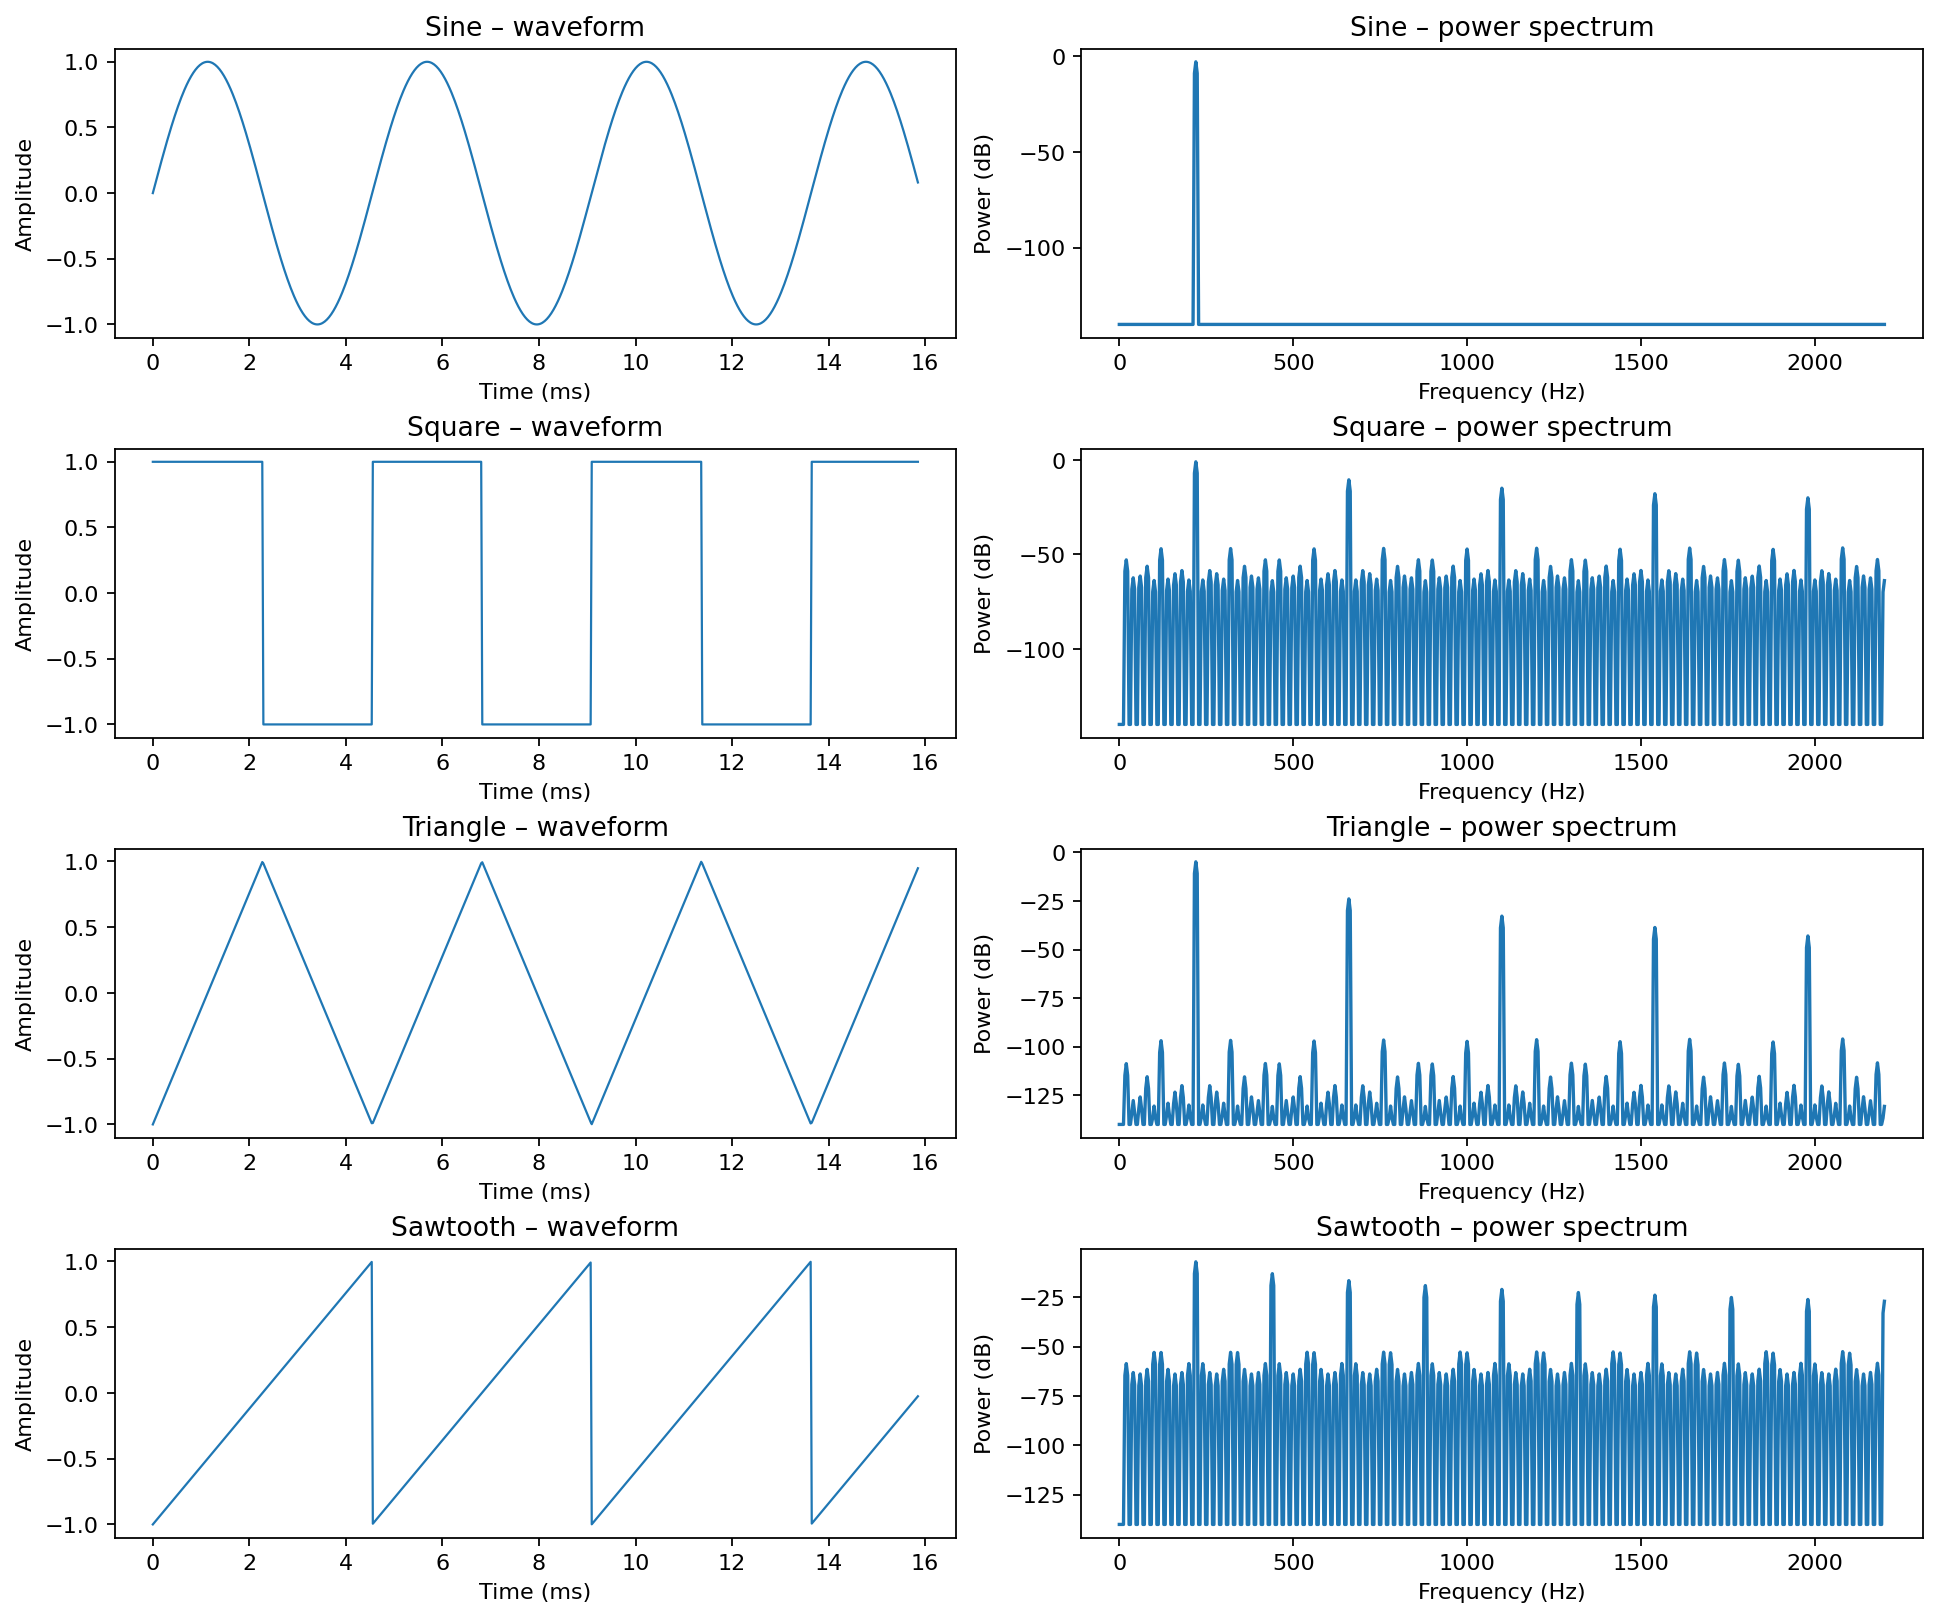

In [2]:
def midi_to_frequency(note):
    return 440.0 * 2.0 ** ((float(note)-69.0)/12.0)

class Oscillator:
    def __init__(self,waveform='sine',frequency=440.0,phase=0.0,volume=1.0,sample_rate=FS):
        self.waveform=waveform
        self.frequency=float(frequency)
        self.phase=float(phase)  # radians
        self.volume=float(volume)
        self.sample_rate=sample_rate

    def generate_wave(self,duration, frequency=None):
        if duration < 0:
            raise ValueError('Duration must be >= 0')
        t=np.arange(round(duration*self.sample_rate))/self.sample_rate
        f=self.frequency if frequency is None else float(frequency)
        phi=2*np.pi*f*t+self.phase
        if self.waveform == 'sine': y=np.sin(phi)
        elif self.waveform == 'square': y=signal.square(phi)
        elif self.waveform == 'triangle': y=signal.sawtooth(phi,width=0.5)
        elif self.waveform == 'sawtooth': y=signal.sawtooth(phi)
        else: raise ValueError('Unsupported waveform '+str(self.waveform))
        return self.volume*y

    def apply_vcf(self,x,cutoff_hz=850.0,resonance=0.707):
        return voltage_controlled_filter(x,cutoff_hz,resonance,self.sample_rate)

def detuned_voice(note=69,duration=0.4,waveform='sine',cents=(-9,0,9),weights=(0.75,1,0.75),velocity=1):
    if len(cents)!=len(weights) or not cents:raise ValueError('cents and weights mismatch')
    base=midi_to_frequency(note)
    acc=np.zeros(round(duration*FS))
    for c,w in zip(cents,weights):
        acc += w*Oscillator(waveform, base*2**(c/1200)).generate_wave(duration)
    return velocity * acc/sum(abs(w) for w in weights)

fig,axs=plt.subplots(4,2,figsize=(12,10),layout='constrained')
for j,kind in enumerate(['sine','square','triangle','sawtooth']):
    wave=Oscillator(kind,220).generate_wave(0.25)
    axs[j,0].plot(np.arange(700)/FS*1000,wave[:700],linewidth=1)
    axs[j,0].set(title=f'{kind.title()} – waveform',ylabel='Amplitude',xlabel='Time (ms)')
    fq,pow=signal.periodogram(wave,FS,window='hann',scaling='spectrum')
    mask=(fq>=0)&(fq<=2200)
    axs[j,1].plot(fq[mask],10*np.log10(np.maximum(pow[mask],1e-14)))
    axs[j,1].set(title=f'{kind.title()} – power spectrum',xlabel='Frequency (Hz)',ylabel='Power (dB)')
save_fig('01_oscillators.png')
assert midi_to_frequency(69)==440
assert abs(midi_to_frequency(81)-880)<1e-8
print('Detuned A4 voice:',metrics(detuned_voice()))
# Individual oscillator and detuned-voice WAV demonstrations
for kind in ('sine','square','triangle','sawtooth'):
    save_audio('osc_'+kind+'.wav',Oscillator(kind,220).generate_wave(.7))
save_audio('osc_detuned.wav',detuned_voice(69,1.0,'sine',(-9,0,9)))

## 3. AHDSR envelope and note shaping
The five stages are Attack, Hold, Decay, Sustain and Release. The note-on time determines the beginning of the sustained portion and the note-off time starts a smooth release. Attack/hold/decay intervals are clipped gracefully if the note is short. A continuous, nonnegative envelope avoids discontinuities at note boundaries.

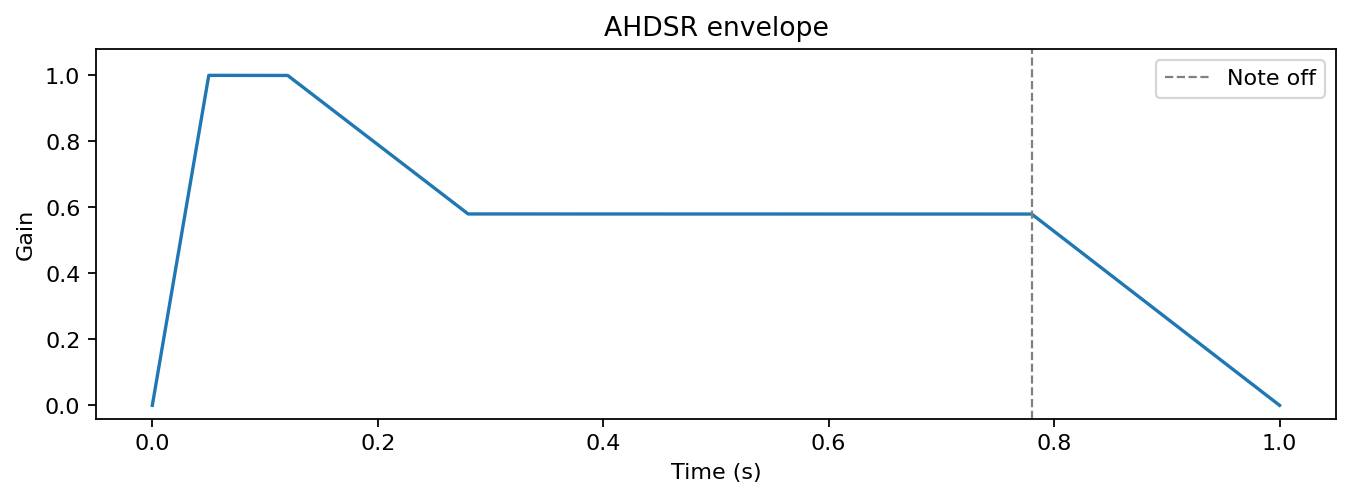

In [3]:
@dataclass(frozen=True)
class AHDSR:
    attack: float=0.025
    hold: float=0.025
    decay: float=0.09
    sustain_level: float=0.64
    release: float=0.14

    def envelope(self,note_duration,fs=FS):
        if note_duration < 0: raise ValueError('Negative note length')
        if not (0<=self.sustain_level<=1): raise ValueError('sustain_level must be between 0 and 1')
        n_on=max(1,round(note_duration*fs)); nr=max(1,round(self.release*fs))
        on=np.zeros(n_on,dtype=float)
        a=min(n_on,round(self.attack*fs)); h=min(n_on-a,round(self.hold*fs))
        d=min(n_on-a-h,round(self.decay*fs))
        idx=0
        if a: on[idx:idx+a]=np.linspace(0,1,a,endpoint=False);idx+=a
        if h: on[idx:idx+h]=1;idx+=h
        if d: on[idx:idx+d]=np.linspace(1,self.sustain_level,d,endpoint=False);idx+=d
        if idx<n_on: on[idx:]=self.sustain_level if d>0 or h>0 or a>0 else 1
        # Explicit note-off release starts at the actual final note-on amplitude.
        rel=np.linspace(on[-1],0,nr,endpoint=True)
        return np.r_[on,rel]

env=AHDSR(0.05,0.07,0.16,0.58,0.22).envelope(0.78)
fig,ax=plt.subplots(figsize=(10,3))
ax.plot(np.arange(len(env))/FS,env)
ax.axvline(0.78,color='gray',ls='--',lw=1,label='Note off')
ax.set(title='AHDSR envelope',xlabel='Time (s)',ylabel='Gain',ylim=(-0.04,1.08))
ax.legend();save_fig('02_ahdsr.png')
assert np.isclose(env[-1],0) and env.min()>=0 and env.max()<=1
# Audio note with full attack, hold, decay, sustain and release
_env=AHDSR(.05,.07,.14,.6,.2).envelope(.55)
save_audio('ahdsr_note.wav',Oscillator('sawtooth',220).generate_wave(len(_env)/FS)*_env)

## 4. MIDI parsing, timing and polyphonic rendering
MIDI event delta-times are converted to absolute time using the MIDI file tempo map. Note-on messages with zero velocity are note-offs; simultaneous notes are summed into the same audio timeline, not concatenated. Voices are indexed by MIDI channel and pitch so overlapping notes and repeated note numbers are handled explicitly.

note,frequency_Hz,velocity,start_s,end_s,duration_s
43,98.00,127,0.00,0.50,0.50
50,146.83,127,0.50,1.00,0.50
50,146.83,127,1.00,1.50,0.50
46,116.54,127,1.50,2.00,0.50
45,110.00,127,2.00,2.50,0.50
45,110.00,127,2.50,2.75,0.25
43,98.00,127,2.75,3.00,0.25
45,110.00,127,3.00,3.25,0.25
43,98.00,127,3.25,3.50,0.25
45,110.00,127,3.50,3.75,0.25


note  frequency_Hz  velocity  start_s  end_s  duration_s
0     43         98.00       127     0.00   0.50        0.50
1     50        146.83       127     0.50   1.00        0.50
2     50        146.83       127     1.00   1.50        0.50
3     46        116.54       127     1.50   2.00        0.50
4     45        110.00       127     2.00   2.50        0.50
5     45        110.00       127     2.50   2.75        0.25
6     43         98.00       127     2.75   3.00        0.25
7     45        110.00       127     3.00   3.25        0.25
8     43         98.00       127     3.25   3.50        0.25
9     45        110.00       127     3.50   3.75        0.25
10    46        116.54       127     3.75   4.00        0.25
Notes: 11 | channels: 1 | MIDI audio length: 4.170s


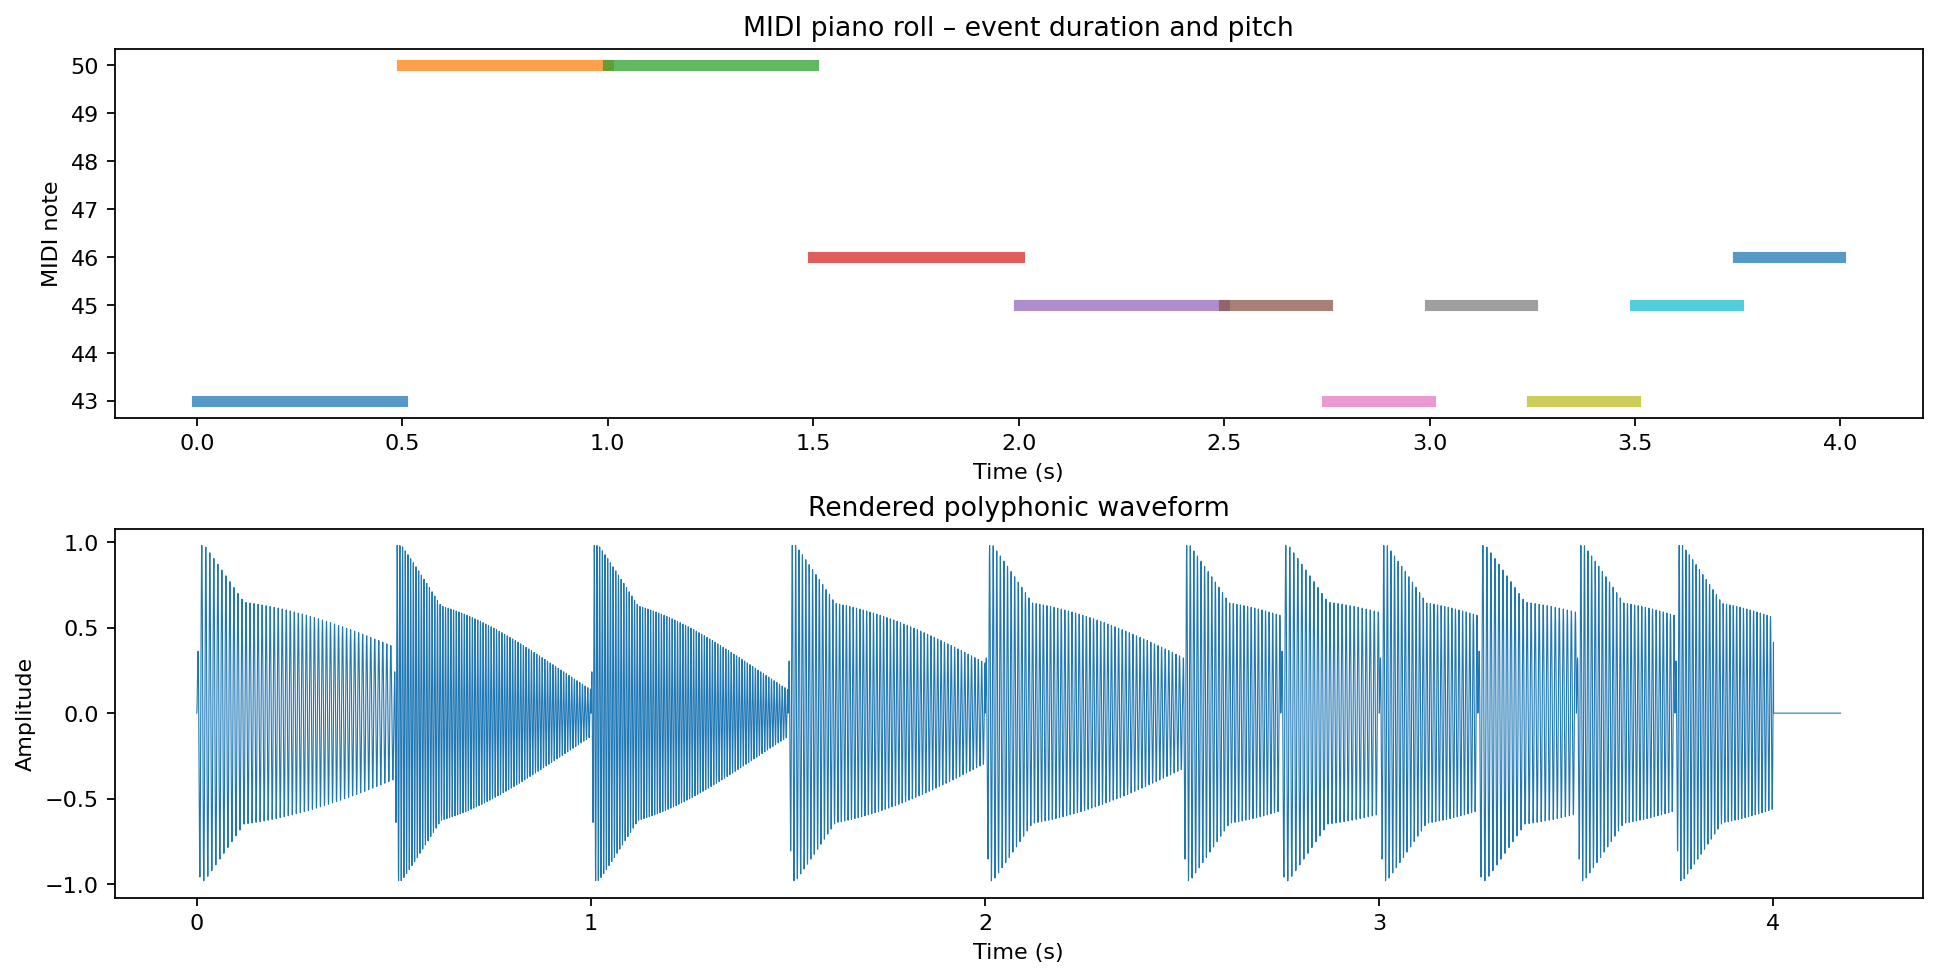

In [4]:
@dataclass(frozen=True)
class NoteEvent:
    channel: int
    note: int
    velocity: int
    start_s: float
    end_s: float
    @property
    def length_s(self): return self.end_s-self.start_s

def parse_midi_events(path):
    mid=mido.MidiFile(path)
    # mido's merged iteration yields messages with seconds in their .time property.
    now=0.0; playing=defaultdict(deque); events=[]
    for msg in mid:
        now+=msg.time
        if msg.type not in ('note_on','note_off'):continue
        key=(msg.channel,msg.note)
        if msg.type=='note_on' and msg.velocity>0:
            playing[key].append((now,msg.velocity))
        elif playing[key]:
            start,vel=playing[key].popleft()
            if now>start:events.append(NoteEvent(msg.channel,msg.note,vel,start,now))
    return sorted(events,key=lambda e:(e.start_s,e.channel,e.note)),mid

midi_events,midi_file=parse_midi_events(ASSETS/'newSong.mid')
if not midi_events: raise RuntimeError('No valid note pairs in MIDI input')
event_table=pd.DataFrame([{'note':e.note,'frequency_Hz':round(midi_to_frequency(e.note),2),
 'velocity':e.velocity,'start_s':round(e.start_s,3),'end_s':round(e.end_s,3),
 'duration_s':round(e.length_s,3)} for e in midi_events])
display(event_table)

DEFAULT_AHDSR=AHDSR(attack=0.008,hold=0.012,decay=0.10,sustain_level=0.68,release=0.12)
def render_midi(events,waveform='sine',detune_cents=(-7,0,7),env=DEFAULT_AHDSR):
    duration=max(e.end_s for e in events)+env.release+0.05
    audio=np.zeros(math.ceil(duration*FS))
    for e in events:
        note_len=e.length_s
        n=detuned_voice(e.note,note_len,waveform,detune_cents,(0.8,1.0,0.8),e.velocity/127)
        enveloped=np.r_[n,np.zeros(max(0,len(env.envelope(note_len))-len(n)))]*env.envelope(note_len)
        start=round(e.start_s*FS)
        end=min(start+len(enveloped),len(audio))
        audio[start:end]+=enveloped[:end-start]
    return audio

midi_synth=save_audio('midi_synthesized.wav',render_midi(midi_events))
print(f'Notes: {len(midi_events)} | channels: {len(set(e.channel for e in midi_events))} | MIDI audio length: {len(midi_synth)/FS:.3f}s')
fig,axs=plt.subplots(2,1,figsize=(12,6),layout='constrained')
for e in midi_events: axs[0].plot([e.start_s,e.end_s],[e.note,e.note],lw=5,alpha=0.75)
axs[0].set(title='MIDI piano roll – event duration and pitch',ylabel='MIDI note',xlabel='Time (s)')
t=np.arange(len(midi_synth))/FS
axs[1].plot(t,midi_synth,lw=0.5)
axs[1].set(title='Rendered polyphonic waveform',ylabel='Amplitude',xlabel='Time (s)')
save_fig('03_midi_timeline.png')

### Alternative MIDI loading and oscillator detuning
The original project also explored a separate MIDI-loader / synthesizer interface and alternative detuning. This implementation retains that use case without duplicating the full signal-processing code. It renders the same source MIDI with triangle oscillators and a wider detuning spread, generating a separate listenable recording. An optional offline text-to-speech utility can create a new speech modulator for the vocoder; the default notebook uses the supplied modulator recording.

In [5]:
class MIDILoader:
    def __init__(self):
        self.events=[]
        self.midi=None
    def load_file(self,filepath):
        self.events,self.midi=parse_midi_events(filepath)
        return self.events
    def get_events(self):
        return list(self.events)

class Synthesizer:
    def __init__(self,waveform='triangle',detune_cents=(-15,0,15)):
        self.waveform=waveform
        self.detune_cents=detune_cents
        self.loader=MIDILoader()
    def load_midi(self,filepath):
        return self.loader.load_file(filepath)
    def render(self):
        if not self.loader.events: raise ValueError('Load a MIDI file first')
        return render_midi(self.loader.events,self.waveform,self.detune_cents)

def save_speech_modulator(text,path):
    """Optional offline voice recording generator; requires pyttsx3 installed locally."""
    import pyttsx3
    engine=pyttsx3.init()
    engine.save_to_file(str(text),str(path))
    engine.runAndWait()
    return Path(path)

alternate_synth=Synthesizer('triangle',(-15,0,15))
alternate_events=alternate_synth.load_midi(ASSETS/'newSong.mid')
alt_synth=save_audio('midi_alternate_detuned.wav',alternate_synth.render())
assert len(alternate_events)==len(midi_events)
print('Alternate MIDI synthesis:', len(alternate_events),'events,',round(len(alt_synth)/FS,3),'seconds')

Alternate MIDI synthesis: 11 events, 4.17 seconds


## 5. Voltage-controlled filter (VCF) and oscillator filtering
A resonant low-pass biquad implements cutoff and resonance control, with resonance parameterized as Q. Coefficients are stable for valid positive Q and cutoffs below Nyquist. The four oscillators are filtered individually, and the higher-harmonic suppression is measured from their spectra.

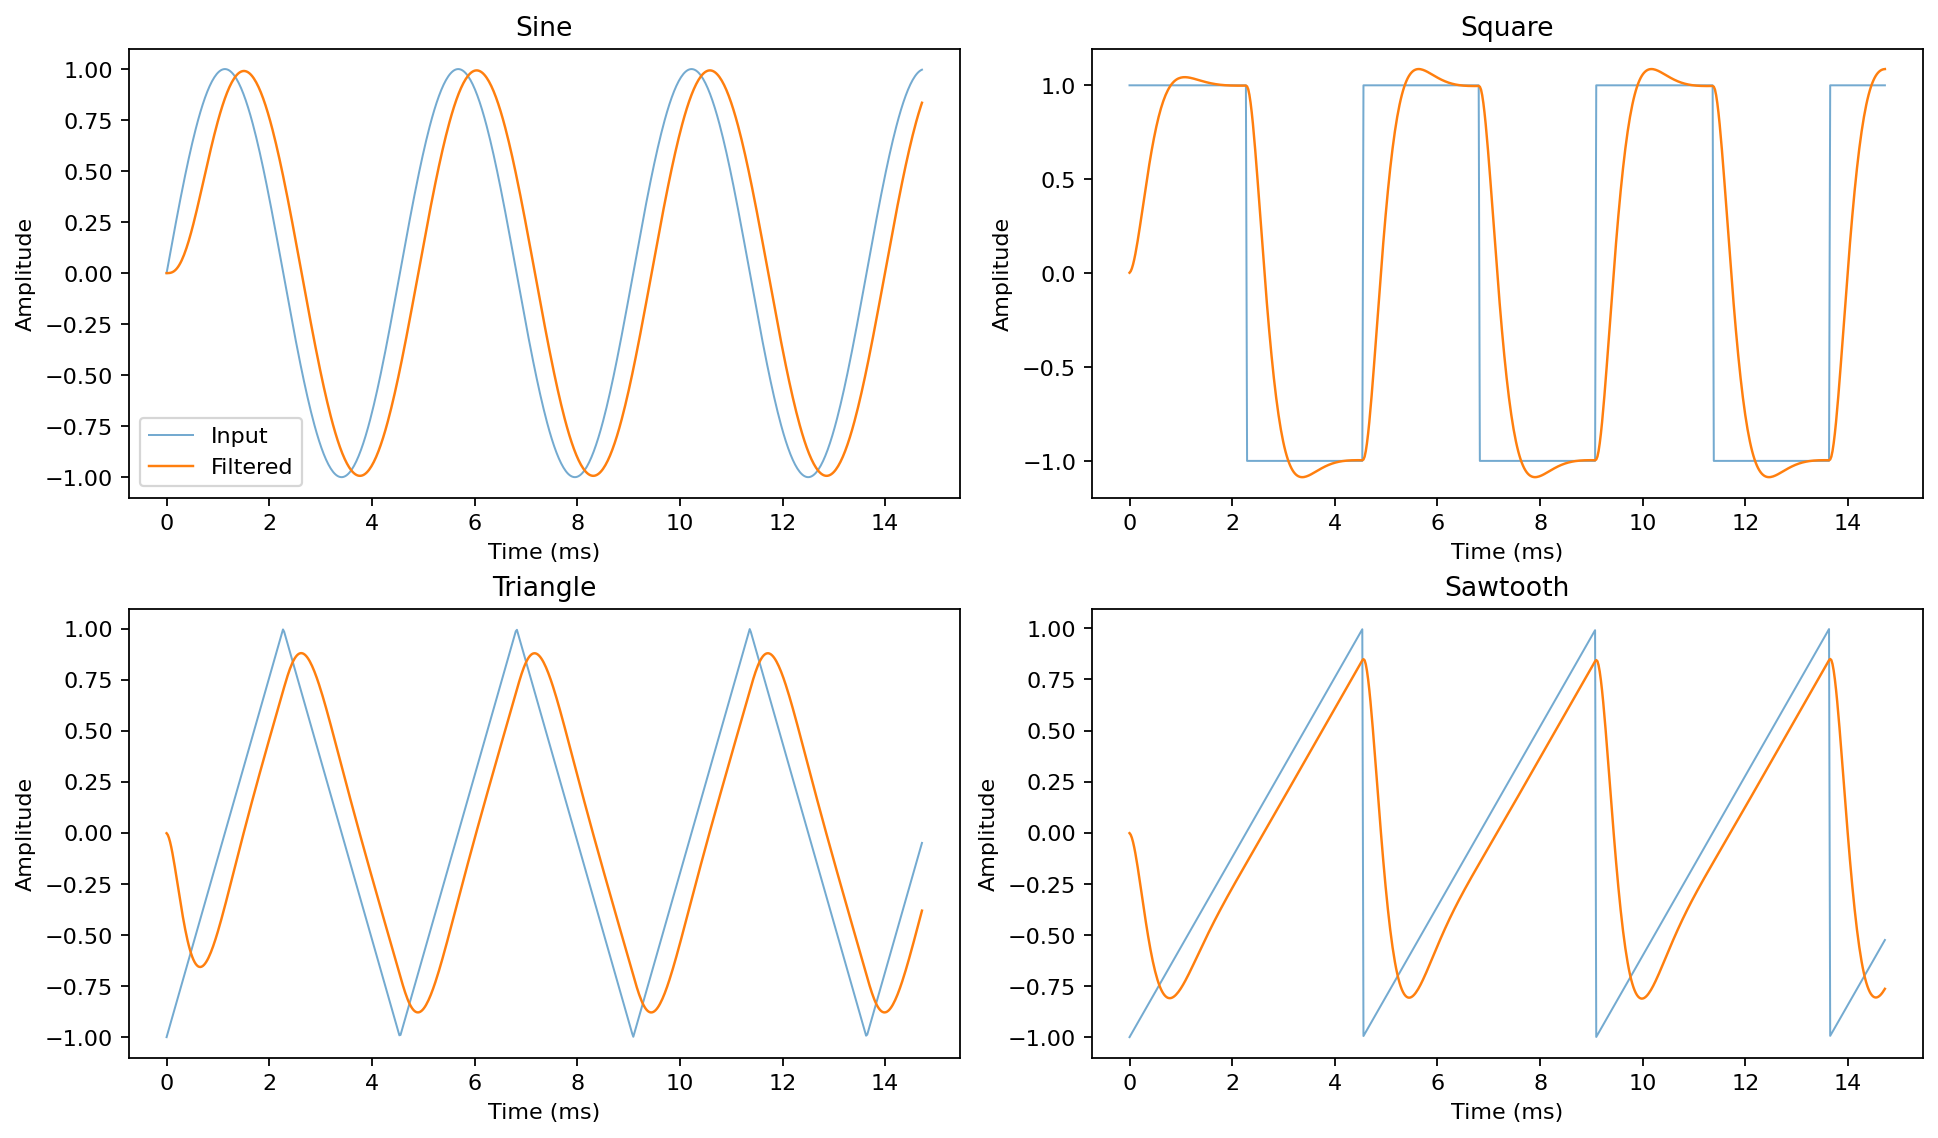

In [6]:
def voltage_controlled_filter(x,cutoff_hz=900.0,resonance=0.707,fs=FS):
    if not 0<cutoff_hz<fs/2:raise ValueError('Invalid cutoff')
    if resonance<=0:raise ValueError('Q must be positive')
    return signal.sosfilt(signal.butter(2,cutoff_hz,btype='low',fs=fs,output='sos'),np.asarray(x)) if resonance==0.707 else signal.sosfilt(
        _biquad_sos(cutoff_hz,resonance,fs),np.asarray(x))

def _biquad_sos(fc,Q,fs):
    w=2*np.pi*fc/fs; a=np.sin(w)/(2*Q); c=np.cos(w)
    b=np.array([(1-c)/2,1-c,(1-c)/2]);den=np.array([1+a,-2*c,1-a])
    return np.array([[*(b/den[0]),1.,den[1]/den[0],den[2]/den[0]]])

fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
vcf_measurements=[]
for kind,ax in zip(['sine','square','triangle','sawtooth'],axs.flat):
    x=Oscillator(kind,220).generate_wave(0.6)
    y=voltage_controlled_filter(x,650,Q if False else 0.707)
    t=np.arange(650)/FS*1000
    ax.plot(t,x[:650],lw=0.9,label='Input',alpha=.62)
    ax.plot(t,y[:650],lw=1.1,label='Filtered')
    ax.set(title=kind.capitalize(),xlabel='Time (ms)',ylabel='Amplitude')
    vc=metrics(y);vcf_measurements.append((kind,vc['rms']))
axs[0,0].legend();save_fig('04_vcf_waveforms.png')
assert all(np.isfinite(v) for _,v in vcf_measurements)
# Filtered oscillator examples for individual listening comparisons
for kind in ('sine','square','triangle','sawtooth'):
    _wave=Oscillator(kind,220).generate_wave(.7)
    save_audio('vcf_'+kind+'.wav',voltage_controlled_filter(_wave,650))

## 6. Effects-rack design
The rack chains effects in order and exposes per-effect input gain, output gain, wet/dry mix and bypass state. Effect implementations retain the distinctions of the original project, including fixed versus LFO-modulated delay, phasing, flanging and chorus. Processing methods operate on normalized mono arrays and preserve input length unless a reverb tail is explicitly requested.

In [7]:
class Effect:
    def __init__(self,name,input_gain=1.,output_gain=1.,wet_dry=1.,active=True):
        self.name=name;self.input_gain=float(input_gain);self.output_gain=float(output_gain)
        self.wet_dry=float(wet_dry);self.active=active
        if not 0<=self.wet_dry<=1: raise ValueError('wet/dry must be in [0,1]')
    def transform(self,x): raise NotImplementedError
    def process(self,x):
        x=np.asarray(x,dtype=float)
        if not self.active:return x.copy()
        wet=self.transform(x*self.input_gain)
        if len(wet)!=len(x):
            if len(wet)>len(x): x=np.pad(x,(0,len(wet)-len(x)))
            else: wet=np.pad(wet,(0,len(x)-len(wet)))
        return self.output_gain*(self.wet_dry*wet+(1-self.wet_dry)*x)

class EffectRack:
    def __init__(self,*effects): self.effects=list(effects)
    def add_effect(self,effect):self.effects.append(effect)
    def remove_effect(self,name):self.effects=[e for e in self.effects if e.name!=name]
    def process(self,x):
        out=np.asarray(x,dtype=float)
        for effect in self.effects:out=effect.process(out)
        return out
    def __repr__(self):return 'EffectRack('+', '.join(e.name for e in self.effects)+')'

class HardClipping(Effect):
    def __init__(self,name='Hard clipping',threshold=.35,**kw):super().__init__(name,**kw);self.threshold=threshold
    def transform(self,x):return np.clip(x,-self.threshold,self.threshold)

class SoftClipping(Effect):
    def __init__(self,name='Soft clipping',threshold=.35,**kw):super().__init__(name,**kw);self.threshold=threshold
    def transform(self,x):return self.threshold*np.tanh(x/max(self.threshold,1e-8))

class VariableSaturation(Effect):
    def __init__(self,name='Variable saturation',drive=2.,bias=0.,shape=.8,**kw):
        super().__init__(name,**kw);self.drive=drive;self.bias=bias;self.shape=shape
    def transform(self,x):
        u=self.drive*x+self.bias
        return np.tanh(self.shape*u)/max(float(np.tanh(self.shape)),1e-8)

class Compressor(Effect):
    def __init__(self,name='Compressor',threshold_db=-16.,ratio=4.,attack=.01,release=.12,fs=FS,**kw):
        super().__init__(name,**kw)
        self.threshold_db=threshold_db;self.ratio=ratio;self.attack=attack;self.release=release;self.fs=fs
    def transform(self,x):
        mag=np.abs(x);envelope=np.empty(len(x))
        a=np.exp(-1/max(1,int(self.fs*self.attack)));r=np.exp(-1/max(1,int(self.fs*self.release)))
        old=0.
        for j,m in enumerate(mag):
            coeff=a if m>old else r;old=coeff*old+(1-coeff)*m;envelope[j]=old
        env_db=20*np.log10(np.maximum(envelope,1e-9))
        gain_db=np.minimum(0.,(self.threshold_db-env_db)*(1-1/self.ratio))
        return x*10**(gain_db/20)

class Delay(Effect):
    def __init__(self,name='Delay',delay_time=.22,feedback=.40,fs=FS,**kw):
        super().__init__(name,**kw);self.delay_time=delay_time;self.feedback=feedback;self.fs=fs
    def transform(self,x):
        delay=max(1,int(self.delay_time*self.fs));y=np.zeros_like(x)
        for i in range(delay,len(x)): y[i]=x[i-delay]+self.feedback*y[i-delay]
        return y

class Delay_with_lfo(Effect):
    def __init__(self,name='Delay with LFO',delay_time=.19,feedback=.38,lfo_freq=.35,lfo_depth=.009,base_cutoff=2200,fs=FS,**kw):
        super().__init__(name,**kw);self.delay_time=delay_time;self.feedback=feedback
        self.lfo_freq=lfo_freq;self.lfo_depth=lfo_depth;self.base_cutoff=base_cutoff;self.fs=fs
    def transform(self,x):
        y=variable_delay(x,self.fs,self.delay_time,self.lfo_depth,self.lfo_freq,self.feedback)
        return voltage_controlled_filter(y,self.base_cutoff,fs=self.fs)

def variable_delay(x,fs,base,depth,rate,feedback=0.,phase=0.):
    if base<=abs(depth):raise ValueError('Delay must exceed modulation depth')
    x=np.asarray(x,dtype=float);n=len(x);y=np.zeros(n)
    for i in range(n):
        delay=(base+depth*np.sin(2*np.pi*rate*i/fs+phase))*fs
        position=i-delay
        if position>=0:
            j=int(position);f=position-j
            prev=y[j]*(1-f)+(y[j+1] if j+1<i else y[j])*f
            dry=x[j]*(1-f)+(x[j+1] if j+1<i else x[j])*f
            y[i]=dry+feedback*prev
    return y

### 6.1 Modulation effects: phaser, flanger and chorus
Fixed and LFO-modulated phasers use cascaded all-pass sections. Flanger and chorus use fractional delays with independently configured delay length, depth and modulation rate. A phaser's moving spectral notches are produced by phase cancellation between dry and all-pass signals, not by simple amplitude modulation.

In [8]:
def phased_allpass(x,fs=FS,rate=.25,depth=.65,stages=4,feedback=0.,fixed=False):
    x=np.asarray(x,dtype=float);y=np.zeros_like(x); z_in=np.zeros(stages);z_out=np.zeros(stages);feedback_state=0.
    for i,sample in enumerate(x):
        u=sample+feedback*feedback_state
        lfo=0. if fixed else np.sin(2*np.pi*rate*i/fs)
        # stable allpass coefficient: a = (tan(pi*f/fs)-1)/(tan(pi*f/fs)+1)
        fc=350.0*(2**(2.0*depth*lfo))
        k=np.tan(np.pi*fc/fs);a=(k-1)/(k+1)
        for st in range(stages):
            v=a*u + z_in[st]-a*z_out[st]
            z_in[st]=u;z_out[st]=v;u=v
        y[i]=u;feedback_state=u
    return y

class Phaser(Effect):
    def __init__(self,name='Phaser',fs=FS,**kw):super().__init__(name,**kw);self.fs=fs
    def transform(self,x):return phased_allpass(x,self.fs,fixed=True)
class Phaser_with_lfo(Effect):
    def __init__(self,name='Phaser with LFO',rate=.6,depth=.6,feedback=.18,num_stages=4,fs=FS,**kw):
        super().__init__(name,**kw);self.rate=rate;self.depth=depth;self.feedback=feedback;self.num_stages=num_stages;self.fs=fs
    def transform(self,x):return phased_allpass(x,self.fs,self.rate,self.depth,self.num_stages,self.feedback)

class Flanger(Effect):
    def __init__(self,name='Flanger',delay_time=.006,depth=.0016,rate=.3,feedback=.32,fs=FS,**kw):
        super().__init__(name,**kw);self.delay_time=delay_time;self.depth=depth;self.rate=rate;self.feedback=feedback;self.fs=fs
    def transform(self,x):return variable_delay(x,self.fs,self.delay_time,self.depth,0.,self.feedback)
class Flanger_with_lfo(Flanger):
    def __init__(self,name='Flanger with LFO',**kw):super().__init__(name,**kw)
    def transform(self,x):return variable_delay(x,self.fs,self.delay_time,self.depth,self.rate,self.feedback)
class Chorus(Effect):
    def __init__(self,name='Chorus',delay_time=.028,depth=.004,rate=.3,fs=FS,**kw):
        super().__init__(name,**kw);self.delay_time=delay_time;self.depth=depth;self.rate=rate;self.fs=fs
    def transform(self,x):return variable_delay(x,self.fs,self.delay_time,self.depth,0,0)
class Chorus_with_lfo(Chorus):
    def __init__(self,name='Chorus with LFO',**kw):super().__init__(name,**kw)
    def transform(self,x):
        return .5*(variable_delay(x,self.fs,self.delay_time,self.depth,self.rate,0)+
                   variable_delay(x,self.fs,self.delay_time*1.18,self.depth*.7,self.rate*.78,0,phase=1.2))

### 6.2 Algorithmic and convolution reverberation
Algorithmic reverb combines multiple feedback comb delays. Convolution reverb filters the signal with measured room impulse responses. All four original room responses are included; their durations and the resultant reverberant tails are retained for comparison.

In [9]:
class Reverberation(Effect):
    def __init__(self,name='Digital reverb',delay_times=(.029,.037,.041,.053),feedback=.52,fs=FS,**kw):
        super().__init__(name,**kw);self.delay_times=delay_times;self.feedback=feedback;self.fs=fs
    def transform(self,x):
        acc=np.zeros_like(x)
        for delay in self.delay_times:
            d=max(1,round(delay*self.fs));y=np.zeros(len(x))
            for i in range(d,len(x)):y[i]=x[i-d]+self.feedback*y[i-d]
            acc+=y/len(self.delay_times)
        return acc

class ConvolutionReverb(Effect):
    def __init__(self,name='Convolution reverb',room='Room4.wav',fs=FS,**kw):
        super().__init__(name,**kw);self.room=room;self.fs=fs
    def transform(self,x):
        ir=read_audio(self.room,self.fs)
        ir=ir/(np.max(np.abs(ir))+1e-12)
        y=signal.fftconvolve(x,ir,mode='full')
        return y/(max(np.sqrt(np.sum(ir*ir)),1e-9))

class VoltageControlledFilter(Effect):
    def __init__(self,name='VCF',cutoff_frequency=980,resonance=.9,fs=FS,**kw):
        super().__init__(name,**kw);self.cutoff_frequency=cutoff_frequency;self.resonance=resonance;self.fs=fs
    def transform(self,x):return voltage_controlled_filter(x,self.cutoff_frequency,self.resonance,self.fs)

### 6.3 Filter-bank vocoder and pitch shifter
The vocoder analyzes the modulator in logarithmically spaced bands, extracts and smooths the magnitude envelope in each band, and applies that envelope to the corresponding carrier band. The pitch shifter uses an STFT-based phase vocoder and a final resampling step; it changes pitch while approximately preserving the input duration.

In [10]:
class Vocoder(Effect):
    def __init__(self,name='Vocoder',num_bands=14,modulator_wav='Modulator.mp3',fs=FS,**kw):
        super().__init__(name,**kw);self.num_bands=num_bands;self.modulator_wav=modulator_wav;self.fs=fs
    def transform(self,carrier):
        modulator=read_audio(self.modulator_wav,self.fs)
        if len(modulator)<len(carrier):modulator=np.pad(modulator,(0,len(carrier)-len(modulator)))
        modulator=modulator[:len(carrier)];out=np.zeros_like(carrier)
        edges=np.geomspace(100,min(8000,self.fs*.44),self.num_bands+1)
        for lo,hi in zip(edges[:-1],edges[1:]):
            sos=signal.butter(3,[lo,hi],btype='bandpass',fs=self.fs,output='sos')
            cb=signal.sosfilt(sos,carrier)
            mb=signal.sosfilt(sos,modulator)
            envelope=np.abs(signal.hilbert(mb))
            alpha=np.exp(-1/(.014*self.fs))
            envelope=signal.lfilter([1-alpha],[1,-alpha],envelope)
            out+=cb*(envelope/(np.sqrt(np.mean(cb*cb))+1e-8))
        return out/(np.sqrt(np.mean(out*out))+1e-8)*.12

class PitchShifter(Effect):
    def __init__(self,name='Pitch shifter',semitones=4,fs=FS,**kw):
        super().__init__(name,**kw);self.semitones=semitones;self.fs=fs
    def transform(self,x):
        # libROSA's phase vocoder resynthesis includes phase continuity and length matching.
        import librosa
        y=librosa.effects.pitch_shift(x.astype(np.float64),sr=self.fs,n_steps=self.semitones,res_type='soxr_hq')
        return y[:len(x)] if len(y)>=len(x) else np.pad(y,(0,len(x)-len(y)))

## 7. Independent effect demonstrations and complete audio exports
Every implemented effect type is applied to the actual eight-second source recording using its own instance. The output files preserve distinct processing methods; no effect is substituted or silently omitted. Convolution reverb is evaluated with each of the four supplied room responses, while vocoder uses the full original carrier and modulator recordings.

In [11]:
demos=[
 ('hard_clipping',HardClipping(threshold=.30,wet_dry=.95,input_gain=1.6)),
 ('soft_clipping',SoftClipping(threshold=.33,wet_dry=.95,input_gain=1.8)),
 ('variable_saturation',VariableSaturation(drive=2.2,shape=.72,bias=.015,wet_dry=.85)),
 ('compressor',Compressor(wet_dry=.95,threshold_db=-21,ratio=4)),
 ('delay',Delay(wet_dry=.50,delay_time=.21,feedback=.45)),
 ('delay_lfo',Delay_with_lfo(wet_dry=.50,lfo_depth=.012)),
 ('phaser',Phaser(wet_dry=.65)),
 ('phaser_lfo',Phaser_with_lfo(wet_dry=.66)),
 ('flanger',Flanger(wet_dry=.62)),
 ('flanger_lfo',Flanger_with_lfo(wet_dry=.62)),
 ('chorus',Chorus(wet_dry=.57)),
 ('chorus_lfo',Chorus_with_lfo(wet_dry=.60)),
 ('digital_reverb',Reverberation(wet_dry=.55)),
 ('vcf',VoltageControlledFilter(wet_dry=.95,cutoff_frequency=950,resonance=.88)),
 ('pitch_shift',PitchShifter(wet_dry=1,semitones=4)),
]
recordings={'source':source,'midi_synth':midi_synth,'midi_alternate':alt_synth}
for key,effect in demos:
    y=effect.process(source)
    recordings[key]=save_audio(key+'.wav',y)
    print(f'{key:21s} peak={metrics(y)["peak"]:.3f} RMS={metrics(y)["rms"]:.3f} n={len(y)}')
for ir in ['Room1.wav','Room2.wav','Room3.wav','Room4.wav']:
    key='convolution_'+ir.lower().replace('.wav','')
    y=ConvolutionReverb(room=ir,wet_dry=.55).process(source)
    recordings[key]=save_audio(key+'.wav',y)
    print(f'{key:21s} output_duration={len(y)/FS:.3f}s')
carrier=read_audio('Carrier.mp3')
voc=Vocoder(num_bands=14,wet_dry=1).process(carrier)
recordings['vocoder']=save_audio('vocoder.wav',voc)
print('Vocoder input duration:',len(carrier)/FS,'s')
print('Independent recordings:',len(recordings)-2)

hard_clipping         peak=0.334 RMS=0.228 n=352800
soft_clipping         peak=0.362 RMS=0.233 n=352800
variable_saturation   peak=1.409 RMS=0.601 n=352800
compressor            peak=0.980 RMS=0.101 n=352800
delay                 peak=0.882 RMS=0.212 n=352800
delay_lfo             peak=0.855 RMS=0.231 n=352800
phaser                peak=1.083 RMS=0.310 n=352800
phaser_lfo            peak=1.122 RMS=0.209 n=352800
flanger               peak=1.170 RMS=0.292 n=352800
flanger_lfo           peak=1.174 RMS=0.240 n=352800
chorus                peak=0.932 RMS=0.250 n=352800
chorus_lfo            peak=0.927 RMS=0.191 n=352800
digital_reverb        peak=0.599 RMS=0.144 n=352800
vcf                   peak=1.023 RMS=0.330 n=352800
pitch_shift           peak=1.068 RMS=0.205 n=352800
convolution_room1     output_duration=10.386s
convolution_room2     output_duration=9.298s
convolution_room3     output_duration=11.281s
convolution_room4     output_duration=9.314s
Vocoder input duration: 48.03918367346

## 8. Cascaded effects rack and bypass behavior
A multistage demonstration combines saturation, compression, VCF, chorus, delay and reverb. The rack orders are explicit so the combined signal can be reconstructed from the notebook. Individual instances are stateless between full runs or recreated for each demonstration.

In [12]:
rack=EffectRack(SoftClipping(threshold=.55,input_gain=1.2,wet_dry=.58),
                Compressor(threshold_db=-17,ratio=3.0,wet_dry=.8),
                VoltageControlledFilter(cutoff_frequency=4200,resonance=.9,wet_dry=.7),
                Chorus_with_lfo(wet_dry=.25),
                Delay(delay_time=.19,feedback=.28,wet_dry=.26),
                Reverberation(feedback=.40,wet_dry=.20))
rack_output=save_audio('full_effect_rack.wav',rack.process(source))
recordings['full_rack']=rack_output
print('Rack:',rack)
assert np.allclose(SoftClipping(active=False).process(source[:1000]),source[:1000])
assert np.max(np.abs(rack_output)) <= 1.00001

Rack: EffectRack(Soft clipping, Compressor, VCF, Chorus with LFO, Delay, Digital reverb)


## 9. Signal analysis and quantitative output comparison
The saved effects are compared using duration, sample peak and RMS amplitude. We also present representative waveforms and spectra for representative saturation, compression, VCF, delay and chorus outputs; values are computed from the actual generated arrays.

effect,duration_s,peak,rms,rms_dbfs
ahdsr_note,0.75000,0.98001,0.36174,-8.83219
chorus,8.00000,0.93230,0.25040,-12.02732
chorus_lfo,8.00000,0.92662,0.19111,-14.37416
compressor,8.00000,0.97973,0.10110,-19.90536
convolution_room1,10.38637,0.68377,0.14518,-16.76181
convolution_room2,9.29814,0.98000,0.16477,-15.66224
convolution_room3,11.28127,0.98000,0.17270,-15.25422
convolution_room4,9.31385,0.98000,0.18933,-14.45564
delay,8.00000,0.88190,0.21167,-13.48681
delay_lfo,8.00000,0.85528,0.23129,-12.71673


effect  duration_s     peak      rms  rms_dbfs
13               chorus     8.00000  0.93230  0.25040 -12.02732
14           chorus_lfo     8.00000  0.92662  0.19111 -14.37416
6            compressor     8.00000  0.97973  0.10110 -19.90536
18    convolution_room1    10.38637  0.68377  0.14518 -16.76181
19    convolution_room2     9.29814  0.98000  0.16477 -15.66224
20    convolution_room3    11.28127  0.98000  0.17270 -15.25422
21    convolution_room4     9.31385  0.98000  0.18933 -14.45564
7                 delay     8.00000  0.88190  0.21167 -13.48681
8             delay_lfo     8.00000  0.85528  0.23129 -12.71673
15       digital_reverb     8.00000  0.59939  0.14394 -16.83640
11              flanger     8.00000  0.98000  0.24488 -12.22086
12          flanger_lfo     8.00000  0.98000  0.19994 -13.98190
23            full_rack     8.00000  0.34135  0.07089 -22.98845
3         hard_clipping     8.00000  0.33400  0.22767 -12.85383
2        midi_alternate     4.17000  0.97865  0.30340 -10

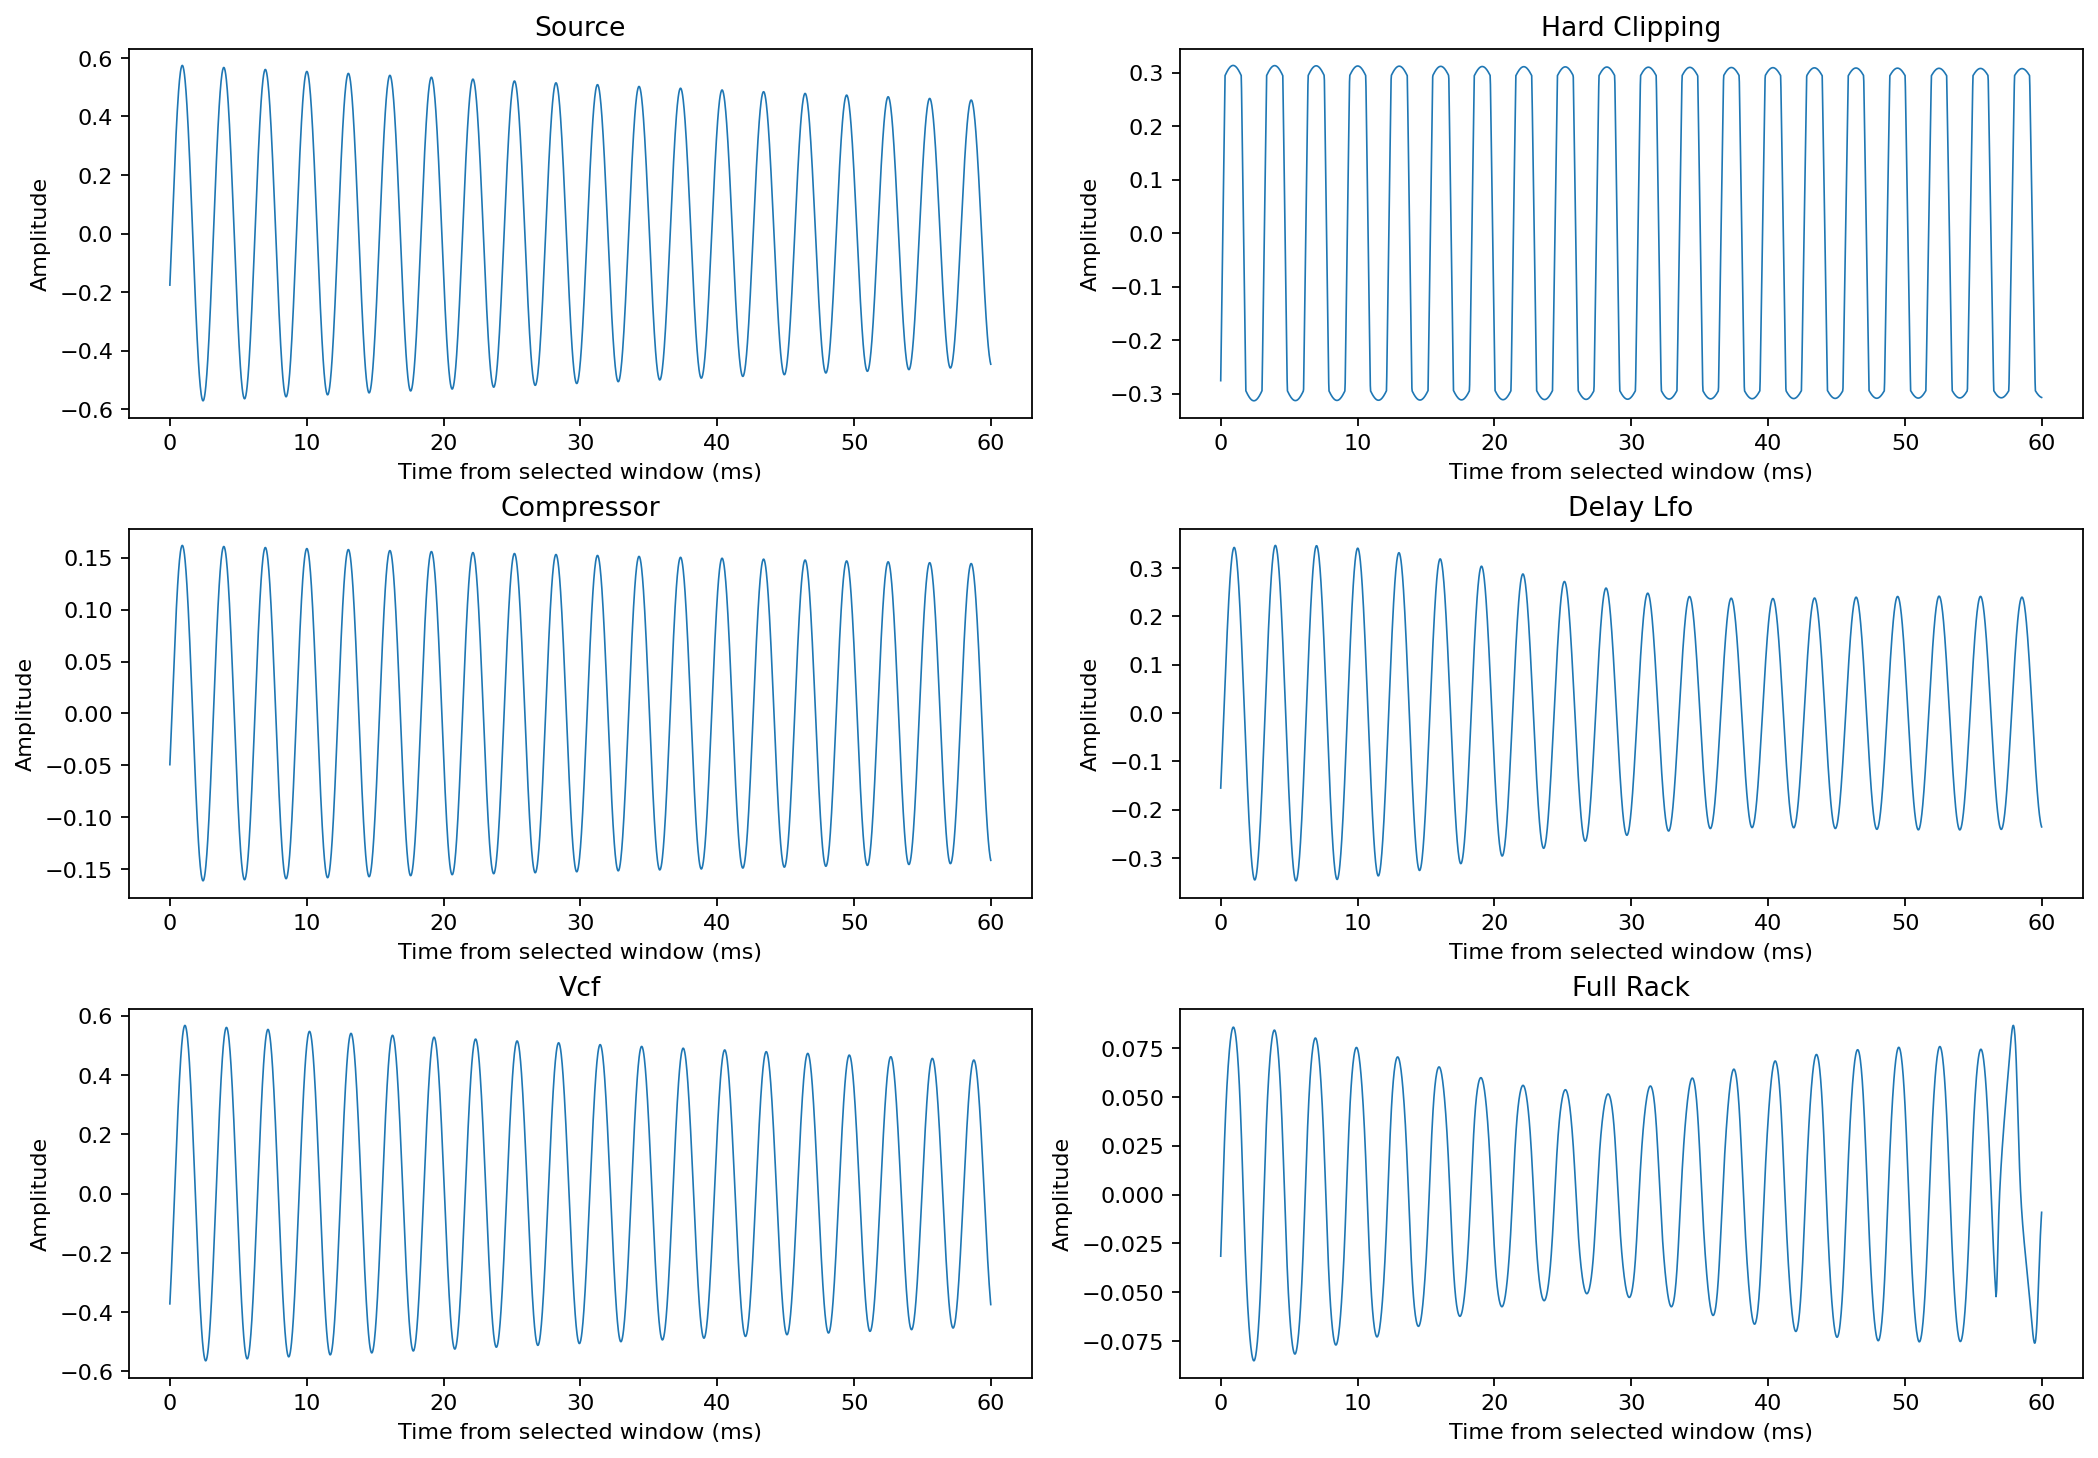

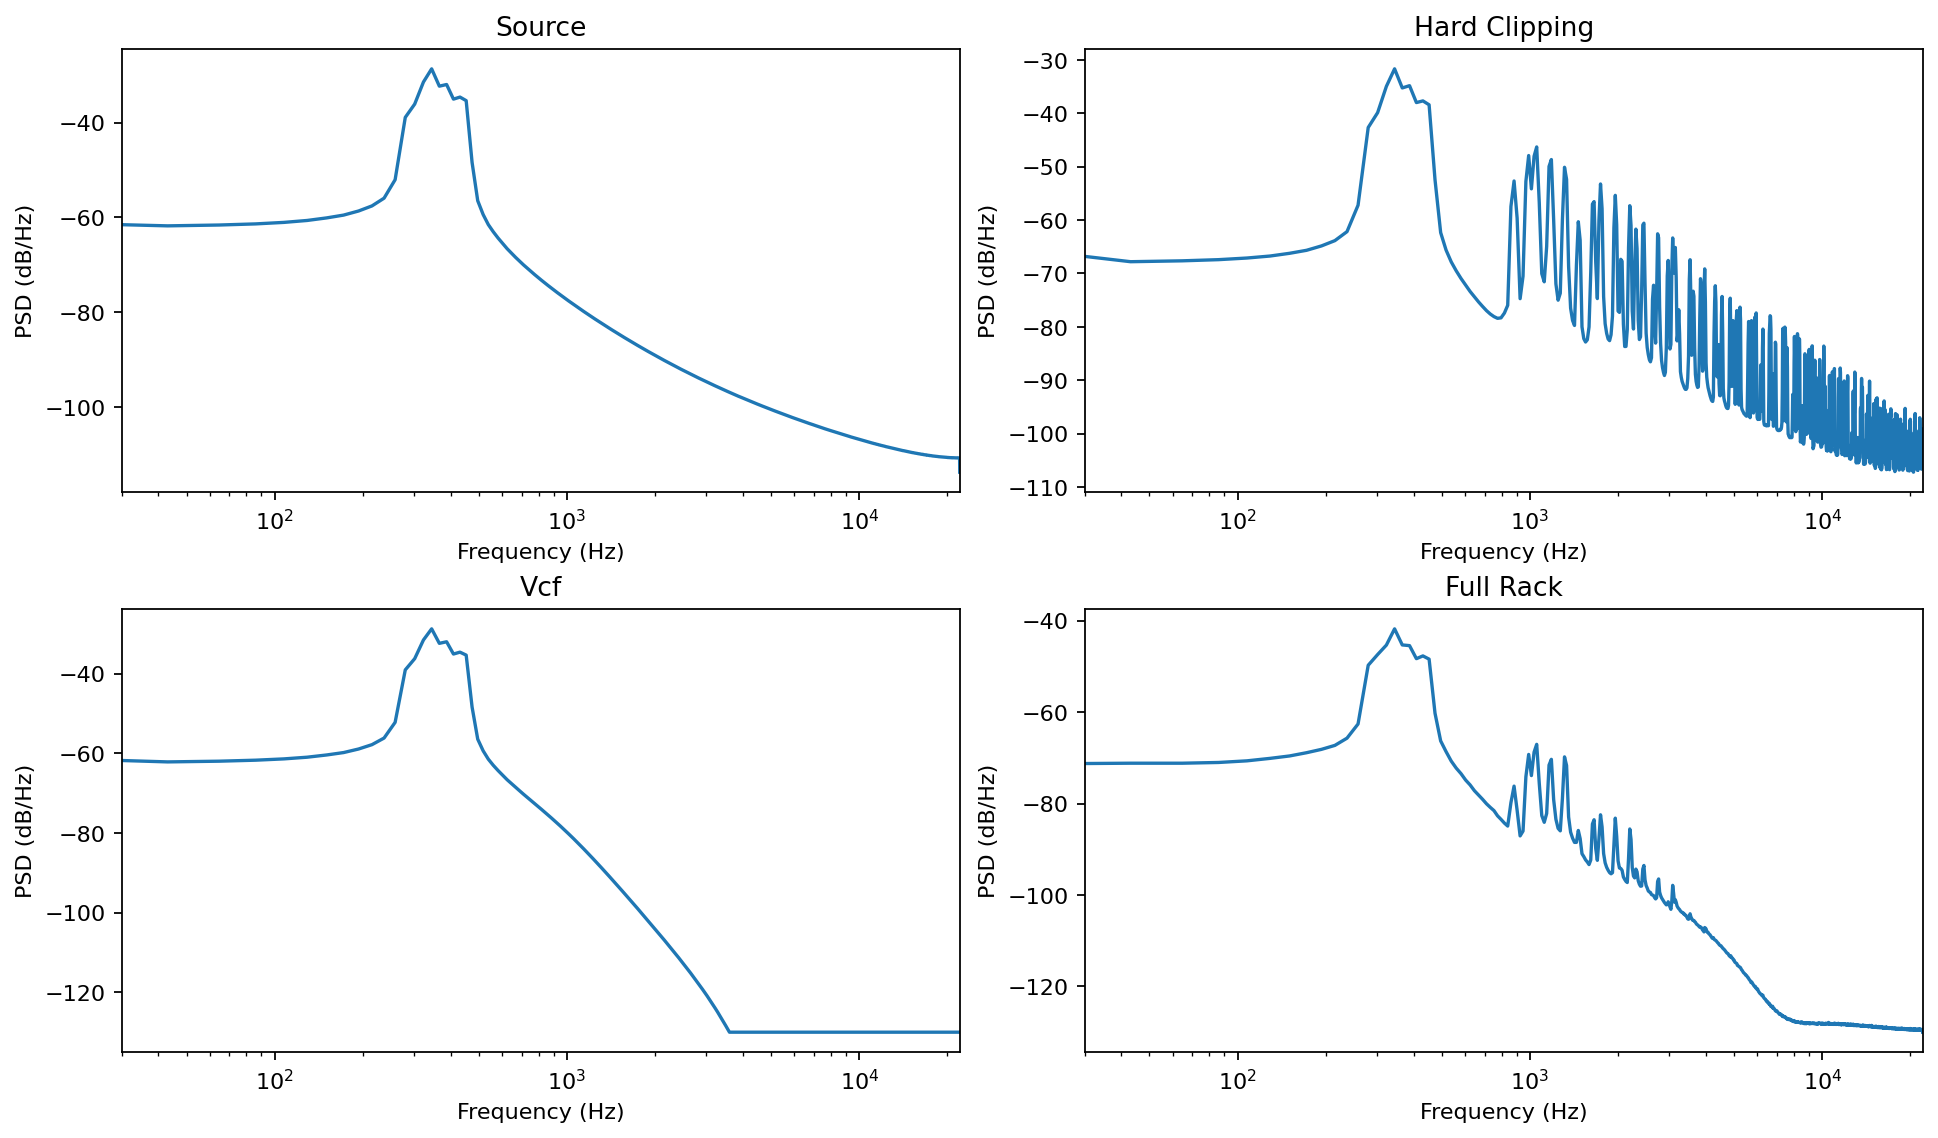

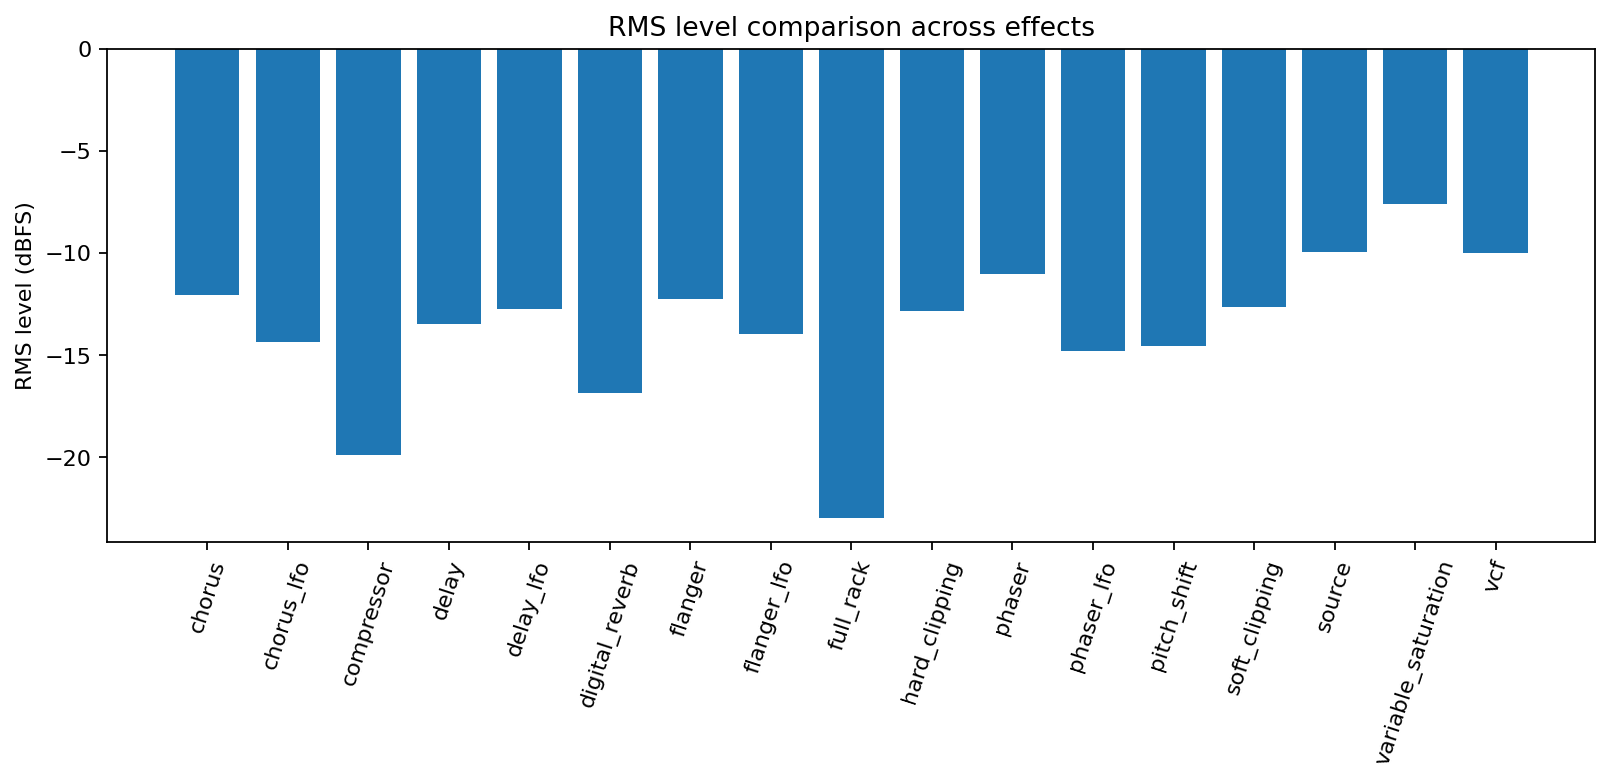

In [13]:
rows=[]
for name,x in recordings.items():
    m=metrics(x);rows.append({'effect':name,**{k:round(v,5) for k,v in m.items()}})
metric_table=pd.DataFrame(rows).sort_values('effect')
display(metric_table)

# Include the oscillator, envelope and filtered-waveform audio demonstrations as well.
for _path in sorted(OUT.glob('osc_*.wav'))+sorted(OUT.glob('vcf_*.wav'))+[OUT/'ahdsr_note.wav']:
    _samples,_sr=sf.read(_path)
    _key=_path.stem
    _m=metrics(_samples)
    metric_table=pd.concat([metric_table,pd.DataFrame([{'effect':_key,**{k:round(v,5) for k,v in _m.items()}}])],ignore_index=True)
metric_table=metric_table.sort_values('effect')
metric_table.to_csv(OUT/'metrics.csv',index=False)

fig,axs=plt.subplots(3,2,figsize=(13,9),layout='constrained')
for ax,key in zip(axs.flat,['source','hard_clipping','compressor','delay_lfo','vcf','full_rack']):
    x=recordings[key]; lo=int(.8*FS);hi=min(lo+int(.06*FS),len(x))
    ax.plot(np.arange(hi-lo)/FS*1000,x[lo:hi],lw=.75)
    ax.set(title=key.replace('_',' ').title(),xlabel='Time from selected window (ms)',ylabel='Amplitude')
save_fig('05_effect_waveforms.png')

fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
for ax,key in zip(axs.flat,['source','hard_clipping','vcf','full_rack']):
    x=recordings[key]
    f,p=signal.welch(x,FS,nperseg=2048)
    ax.semilogx(f[1:],10*np.log10(np.maximum(p[1:],1e-13)))
    ax.set(title=key.replace('_',' ').title(),xlabel='Frequency (Hz)',ylabel='PSD (dB/Hz)',xlim=(30,FS/2))
save_fig('06_effect_spectra.png')

fig,ax=plt.subplots(figsize=(12,4))
comparison=metric_table[metric_table.effect.isin(['source','hard_clipping','soft_clipping','variable_saturation','compressor','delay','delay_lfo','phaser','phaser_lfo','flanger','flanger_lfo','chorus','chorus_lfo','digital_reverb','vcf','pitch_shift','full_rack'])]
ax.bar(comparison.effect,comparison.rms_dbfs)
ax.tick_params(axis='x',rotation=72)
ax.set(title='RMS level comparison across effects',ylabel='RMS level (dBFS)')
save_fig('07_effect_level_comparison.png')

## 10. Verification and replay
These checks cover tuning, output sizes, finiteness, absence of silent removals, bypass operation and MIDI timing. For a compact listening preview, play the synthesized MIDI and selected sound effects; every full recording is already saved in `outputs/`.

In [14]:
assert set(['hard_clipping','soft_clipping','variable_saturation','compressor','delay','delay_lfo',
 'phaser','phaser_lfo','flanger','flanger_lfo','chorus','chorus_lfo','digital_reverb',
 'vcf','pitch_shift','vocoder','full_rack']).issubset(recordings)
for key,y in recordings.items():
    assert np.isfinite(y).all() and len(y)>0, key
    assert np.max(np.abs(y))<=1.00001,key
assert len(read_audio('Carrier.mp3'))==len(recordings['vocoder'])
assert len(list(OUT.glob('*.wav'))) >= 34
assert len(midi_events)>0
assert all(e.start_s<e.end_s for e in midi_events)
assert len(midi_synth)>=int(max(e.end_s for e in midi_events)*FS)
assert (OUT/'metrics.csv').exists()
print('All validation checks passed. Output WAV count:',len(list(OUT.glob('*.wav'))))
display(Audio(filename=str(OUT/'midi_synthesized.wav')))
display(Audio(filename=str(OUT/'full_effect_rack.wav')))

All validation checks passed. Output WAV count: 34
<IPython.lib.display.Audio object>
<IPython.lib.display.Audio object>


Audio preview: midi_synthesized.wav

Audio preview: full_effect_rack.wav